# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [ ]:
%pip install imbalanced-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [15]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        X_with_bias = np.column_stack((np.ones(X.shape[0]), X))
        n_samples, n_weights = X_with_bias.shape

        self.w = (np.zeros(n_weights)
            if self.w0 is None
            else np.asarray(self.w0, dtype=float).copy()
        )

        if self.w.shape != (n_weights,):
            raise ValueError(f'w0 должен иметь размер {(n_weights,)}')

        for _ in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X_with_bias, y))

            if self.gd_type == 'full':
                gradient = self.calc_gradient(X_with_bias, y)
            elif self.gd_type == 'stochastic':
                indices = rng.choice(
                    n_samples,
                    size=min(self.batch_size, n_samples),
                    replace=False
                )
                gradient = self.calc_gradient(
                    X_with_bias[indices], y[indices]
                )
            else:
                raise ValueError("gd_type должен быть 'full' или 'stochastic'")

            new_w = self.w - self.eta * gradient
            step_norm = np.linalg.norm(new_w - self.w)
            self.w = new_w

            if step_norm < self.tolerance:
                break

        return self

    def sigmoid(self, z):
        exp_neg_abs = np.exp(-np.abs(z))
        return np.where(
            z >= 0,
            1 / (1 + exp_neg_abs),
            exp_neg_abs / (1 + exp_neg_abs)
        )

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = np.asarray(X, dtype=float)
        X_with_bias = np.column_stack((np.ones(X.shape[0]), X))
        p1 = self.sigmoid(X_with_bias @ self.w)
        return np.column_stack((1 - p1, p1))

    def predict(self, X, threshold=0.5):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        p1 = self.predict_proba(X)[:, 1]
        return (p1 >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        p1 = self.sigmoid(X @ self.w)
        return X.T @ (p1 - y) / len(y)

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """

        p1 = self.sigmoid(X @ self.w)
        p1 = np.clip(p1, 1e-15, 1 - 1e-15)
        return float(
            -np.mean(y * np.log(p1) + (1 - y) * np.log(1 - p1))
        )

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [16]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.44e-10


Теперь проверим работу класса на синтетических данных.

In [17]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

полный спуск: 1000 итераций, остановка по max_iter
стохастический спуск: 1000 итераций, остановка по max_iter


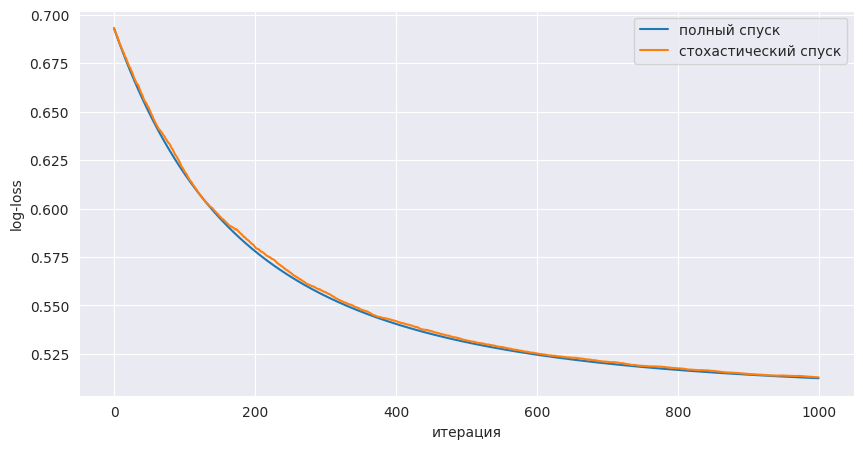

In [20]:
full_model = LogReg(gd_type='full').fit(X_train, y_train)
stochastic_model = LogReg(gd_type='stochastic').fit(X_train, y_train)

for name, model in [
    ('полный спуск', full_model),
    ('стохастический спуск', stochastic_model)
]:
    iterations = len(model.loss_history)
    stop_reason = (
        'tolerance' if iterations < model.max_iter else 'max_iter'
    )
    print(f'{name}: {iterations} итераций, остановка по {stop_reason}')

plt.figure(figsize=(10, 5))
plt.plot(full_model.loss_history, label='полный спуск')
plt.plot(stochastic_model.loss_history, label='стохастический спуск')
plt.xlabel('итерация')
plt.ylabel('log-loss')
plt.legend()
plt.show()

обе модели остановились после 1000 итераций по max_iter, до этого изменения весов не стали меньше tolerance

стохастический спуск каждый раз учится на случайных 32 объектах, поэтому веса меняются немного по-разному

значение eta при этом не уменьшается и из-за этого изменения весов редко становятся достаточно маленькими для остановки по tolerance

на графике ошибка обеих моделей снижается и линии почти совпадают

линия стохастического спуска менее ровная, но не сильно

за одну итерацию полный спуск использует для вычисления градиента все 14000 обучающих объектов, а стохастический спуск 32. при этом для построения обоих графиков ошибка каждый раз считается по всем 14000 объектам

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

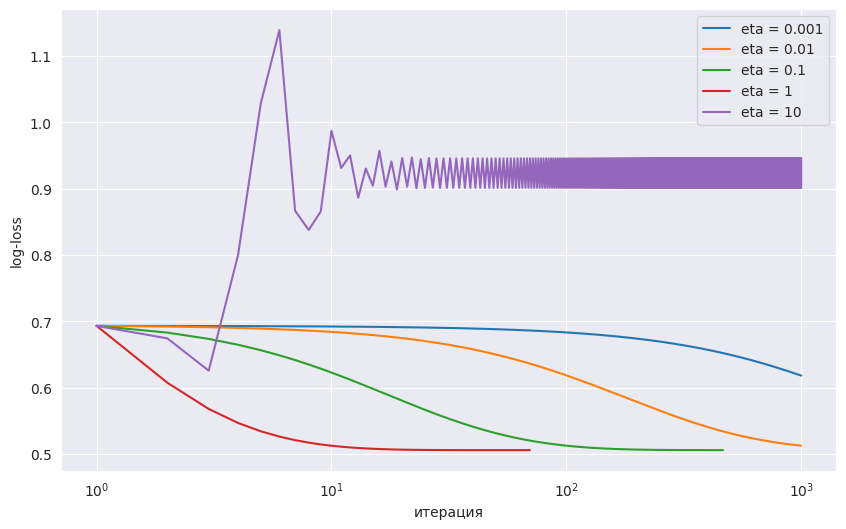

,eta,итераций,финальный log-loss
0,0.001,1000,0.618087
1,0.010,1000,0.512435
2,0.100,465,0.505762
3,1.000,70,0.505757
4,10.000,1000,0.901345


In [19]:
eta_values = [1e-3, 1e-2, 1e-1, 1, 10]
X_train_with_bias = np.column_stack((np.ones(X_train.shape[0]), X_train))
results = []

plt.figure(figsize=(10, 6))

for eta in eta_values:
    model = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)

    results.append({
        'eta': eta,
        'итераций': len(model.loss_history),
        'финальный log-loss': model.calc_loss(X_train_with_bias, y_train)
    })

    plt.plot(
        np.arange(1, len(model.loss_history) + 1),
        model.loss_history,
        label=f'eta = {eta}'
    )

plt.xscale('log')
plt.xlabel('итерация')
plt.ylabel('log-loss')
plt.legend()
plt.show()

display(pd.DataFrame(results))

по графику видно размер шага сильно влияет на обучение

при eta = 0.001 модель учится медленно: за 1000 итераций ошибка снизилась только до 0.618

при eta = 0.01 она снизилась до 0.512, но модель тоже дошла до предела в 1000 итераций

лучший результат дали eta = 0.1 и eta = 1 тогда итоговая ошибка у обеих около 0.506.

при eta = 1 для этого понадобилось 70 итераций, а при eta = 0.1 потребовалось 465

eta = 10 оказался слишком большим на графике ошибка резко меняется и колеблется вместо того, чтобы устойчиво снижаться. её итоговое значение 0.901, это хуже остальных вариантов

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [21]:
sklearn_model = LogisticRegression(random_state=RANDOM_STATE).fit(
    X_train, y_train
)

results = []

for name, model in [
    ('наш полный спуск', full_model),
    ('наш стохастический спуск', stochastic_model),
    ('sklearn', sklearn_model)
]:
    predicted_classes = model.predict(X_test)
    predicted_probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        'модель': name,
        'accuracy': metrics.accuracy_score(y_test, predicted_classes),
        'ROC-AUC': metrics.roc_auc_score(y_test, predicted_probabilities)
    })

display(pd.DataFrame(results))

sklearn_weights = np.concatenate((
    sklearn_model.intercept_,
    sklearn_model.coef_.ravel()
))

weights = pd.DataFrame({
    'вес': [f'w{i}' for i in range(len(full_model.w))],
    'наш полный спуск': full_model.w,
    'sklearn': sklearn_weights
})

display(weights)
print('максимальная разница весов:',
      np.max(np.abs(full_model.w - sklearn_weights)))

,модель,accuracy,ROC-AUC
0,наш полный спуск,0.7820,0.838787
1,наш стохастический спуск,0.7825,0.838115
2,sklearn,0.7765,0.838676


,вес,наш полный спуск,sklearn
0,w0,-0.002114,-0.021880
1,w1,0.006076,0.002741
2,w2,0.006963,0.009039
3,w3,-0.547170,-0.722690
4,w4,-0.144536,-0.262335
5,w5,0.012487,0.016588
6,w6,-0.006325,-0.011488
7,w7,0.000814,0.005587
8,w8,0.039084,0.057188
9,w9,-0.002425,-0.001239


максимальная разница весов: 0.18129404516700065


метрики трёх моделей близки, но не совпадают

accuracy наших моделей около 0.782, у sklearn она равна 0.7765

ROC-AUC у всех трёх моделей около 0.838

веса нашего полного спуска и sklearn различаются: самая большая разница составляет около 0.181

одна из причин в том, что LogisticRegression по умолчанию использует L2-регуляризацию, а в нашем классе её нет

чтобы модели решали одну и ту же задачу оптимизации, регуляризацию в sklearn нужно отключить, например задать penalty=None

но даже после этого веса могут немного различаться, пока наш градиентный спуск не сошёлся: с настройками по умолчанию он остановился после 1000 итераций, потому что достиг max_iter

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [22]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [23]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [24]:
print('пропуски:')
display(df.isna().sum().to_frame('количество'))

print('полные дубликаты:', df.duplicated().sum())
print('доля класса 1 в train:', y_train.mean())
print('доля класса 1 в test:', y_test.mean())

constant_predictions = np.zeros(len(y_test), dtype=int)
constant_accuracy = metrics.accuracy_score(
    y_test, constant_predictions
)

wine_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)
wine_model.fit(X_train, y_train)

wine_predictions = wine_model.predict(X_test)
model_accuracy = metrics.accuracy_score(
    y_test, wine_predictions
)

print('accuracy константной модели:', constant_accuracy)
print('accuracy логистической регрессии:', model_accuracy)

пропуски:


,количество
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


полные дубликаты: 1177
доля класса 1 в train: 0.19661315152848033
доля класса 1 в test: 0.19641025641025642
accuracy константной модели: 0.8035897435897436
accuracy логистической регрессии: 0.82


пропусков в данных нет, полных дубликатов 1177

я не стала удалять дубликаты автоматически, потому что одинаковые измерения могут быть у разных вин
если это повторные записи одного и того же вина, их нужно удалить до разделения на train и test

доля хороших вин в train и test почти одинаковая, около 19,6%
stratify=y нужен, чтобы при разделении сохранить примерно одинаковую долю классов

у модели, которая всегда отвечает 0, accuracy равна 0,804
у логистической регрессии accuracy равна 0,820

accuracy здесь не очень полезная так как даже константная модель получает высокий результат, хотя вообще не находит хорошие вина

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP: 98 TN: 1501 FP: 66 FN: 285
матрица, посчитанная вручную:
[[1501   66]
 [ 285   98]]
матрица sklearn:
[[1501   66]
 [ 285   98]]


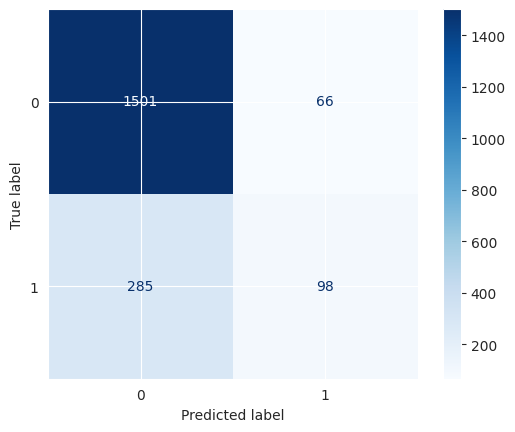

In [25]:
y_true = y_test.to_numpy()

tp = np.sum((y_true == 1) & (wine_predictions == 1))
tn = np.sum((y_true == 0) & (wine_predictions == 0))
fp = np.sum((y_true == 0) & (wine_predictions == 1))
fn = np.sum((y_true == 1) & (wine_predictions == 0))

manual_matrix = np.array([[tn, fp], [fn, tp]])
sklearn_matrix = metrics.confusion_matrix(y_true, wine_predictions)

print('TP:', tp, 'TN:', tn, 'FP:', fp, 'FN:', fn)
print('матрица, посчитанная вручную:')
print(manual_matrix)
print('матрица sklearn:')
print(sklearn_matrix)

metrics.ConfusionMatrixDisplay(
    confusion_matrix=sklearn_matrix,
    display_labels=[0, 1]
).plot(cmap='Blues')

plt.show()

матрица ошибок, посчитанная вручную, совпала с результатом sklearn

модель правильно рекомендовала 98 хороших вин и правильно отклонила 1501 вино

FP = 66 означает, что модель рекомендовала вино, которое на самом деле не было хорошим

FN = 285 означает, что модель пропустила хорошее вино. пропущенных хороших вин заметно больше, чем ошибочных рекомендаций

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [26]:
precision_manual = tp / (tp + fp) if tp + fp > 0 else 0
recall_manual = tp / (tp + fn) if tp + fn > 0 else 0

def calculate_fbeta(precision, recall, beta):
    denominator = beta**2 * precision + recall
    if denominator == 0:
        return 0
    return (1 + beta**2) * precision * recall / denominator

manual_values = {
    'precision': precision_manual,
    'recall': recall_manual,
    'F1': calculate_fbeta(precision_manual, recall_manual, 1),
    'F0.5': calculate_fbeta(precision_manual, recall_manual, 0.5),
    'F2': calculate_fbeta(precision_manual, recall_manual, 2)
}

sklearn_values = {
    'precision': metrics.precision_score(y_true, wine_predictions),
    'recall': metrics.recall_score(y_true, wine_predictions),
    'F1': metrics.fbeta_score(y_true, wine_predictions, beta=1),
    'F0.5': metrics.fbeta_score(y_true, wine_predictions, beta=0.5),
    'F2': metrics.fbeta_score(y_true, wine_predictions, beta=2)
}

display(pd.DataFrame({
    'вручную': manual_values,
    'sklearn': sklearn_values
}))

,вручную,sklearn
precision,0.597561,0.597561
recall,0.255875,0.255875
F1,0.358318,0.358318
F0.5,0.471607,0.471607
F2,0.288915,0.288915


значения, посчитанные вручную, совпали с результатами sklearn

precision равен 0,598, а recall равен 0,256 значит среди рекомендованных вин около 60% хороших, но модель находит только около 26% всех хороших вин

в F_0.5 больше ценится precision

эту метрику я бы выбрала, если подписчики особенно плохо реагируют на посредственные вина в подборке

в F_2 больше ценится recall, поэтому она лучше подходит для сервиса, который хочет показать как можно больше хороших вин

F_1 учитывает обе метрики без такого предпочтения

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

итераций нашего LogReg: 4715
обучение остановилось по: tolerance


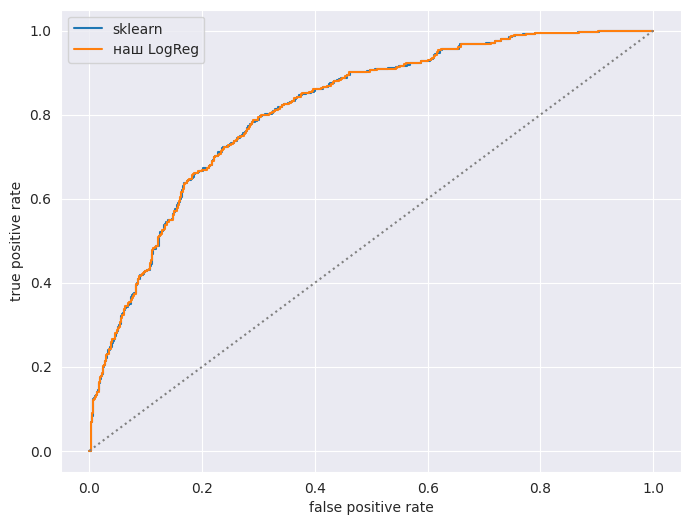

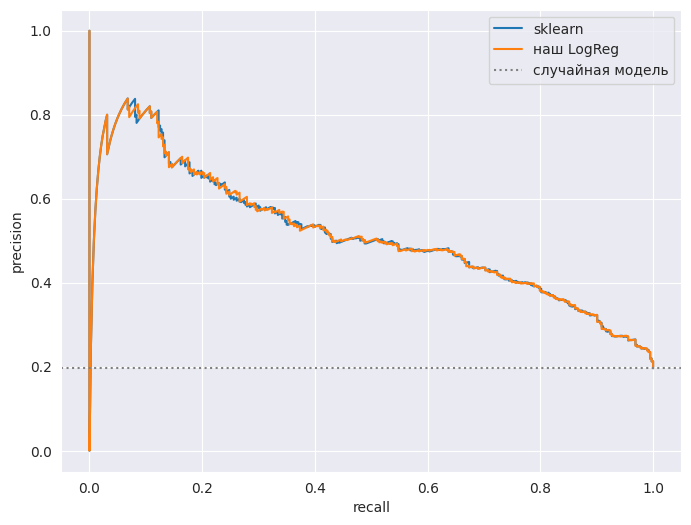

,модель,ROC-AUC,PR-AUC
0,sklearn,0.813537,0.512115
1,наш LogReg,0.813518,0.512273


,оценка,ROC-AUC
0,p,0.813537
1,10p,0.813537
2,p³,0.813537
3,log(p / (1-p)),0.813537
4,-p,0.186463


ROC-AUC по меткам классов: 0.6068779877399565


In [27]:
wine_scaler = StandardScaler()
X_train_scaled = wine_scaler.fit_transform(X_train)
X_test_scaled = wine_scaler.transform(X_test)

custom_wine_model = LogReg(
    gd_type='full',
    eta=0.5,
    max_iter=10000,
    tolerance=1e-5
).fit(X_train_scaled, y_train)

print('итераций нашего LogReg:', len(custom_wine_model.loss_history))
print(
    'обучение остановилось по:',
    'tolerance'
    if len(custom_wine_model.loss_history) < custom_wine_model.max_iter
    else 'max_iter'
)

scores = {
    'sklearn': wine_model.predict_proba(X_test)[:, 1],
    'наш LogReg': custom_wine_model.predict_proba(X_test_scaled)[:, 1]
}

auc_results = []

plt.figure(figsize=(8, 6))

for name, probabilities in scores.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, probabilities)
    plt.plot(fpr, tpr, label=name)

    auc_results.append({
        'модель': name,
        'ROC-AUC': metrics.roc_auc_score(y_test, probabilities),
        'PR-AUC': metrics.average_precision_score(y_test, probabilities)
    })

plt.plot([0, 1], [0, 1], linestyle=':', color='gray')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.legend()
plt.show()

plt.figure(figsize=(8, 6))

for name, probabilities in scores.items():
    precision_curve, recall_curve, _ = metrics.precision_recall_curve(
        y_test, probabilities
    )
    plt.plot(recall_curve, precision_curve, label=name)

plt.axhline(y_test.mean(), linestyle=':', color='gray',
            label='случайная модель')
plt.xlabel('recall')
plt.ylabel('precision')
plt.legend()
plt.show()

display(pd.DataFrame(auc_results))

p = scores['sklearn']
p_safe = np.clip(p, 1e-15, 1 - 1e-15)

transformed_scores = {
    'p': p,
    '10p': 10 * p,
    'p³': p**3,
    'log(p / (1-p))': np.log(p_safe / (1 - p_safe)),
    '-p': -p
}

display(pd.DataFrame([
    {
        'оценка': name,
        'ROC-AUC': metrics.roc_auc_score(y_test, values)
    }
    for name, values in transformed_scores.items()
]))

print(
    'ROC-AUC по меткам классов:',
    metrics.roc_auc_score(y_test, wine_predictions)
)

обе модели работают почти одинаково

у sklearn ROC-AUC равен 0,813537, у нашего LogReg 0,813518

по PR-AUC наш LogReg немного выше: 0,512273 против 0,512115

порядок моделей по двум метрикам различается, но разница очень мала

уровень случайной модели на PR-графике равен доле хороших вин в тесте, около 0,196, а не 0,5

преобразования 10p, p^3 и log(p / (1-p)) сохраняют порядок вин по оценке, поэтому ROC-AUC остаётся 0,813537

преобразование -p меняет порядок на обратный и ROC-AUC снижается до 0,186463

если передать в roc_auc_score готовые метки 0 и 1, получится около 0,607

это меньше 0,814, потому что метки скрывают разницу между вероятностями отдельных вин и теряется информация об их порядке

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

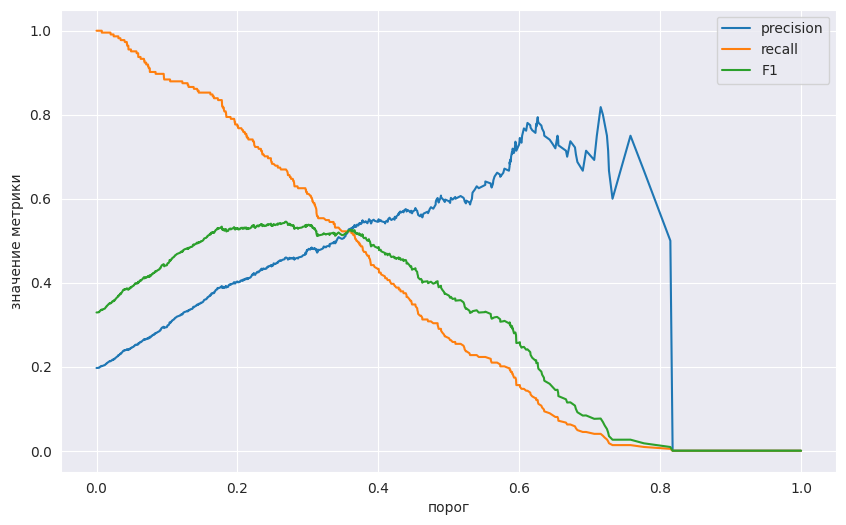

порог для максимального F1: 0.2688887270064323
порог при recall не ниже 0.7: 0.24319636418160753


,порог,значение порога,precision,recall,F1
0,0.5,0.500000,0.597561,0.255875,0.358318
1,максимальный F1,0.268889,0.473888,0.639687,0.544444
2,recall не ниже 0.7,0.243196,0.436975,0.678851,0.531697


In [28]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=RANDOM_STATE
)

validation_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)
validation_model.fit(X_fit, y_fit)

validation_probabilities = validation_model.predict_proba(X_val)[:, 1]
thresholds = np.unique(
    np.r_[0.0, validation_probabilities, 1.0]
)

validation_results = []

for threshold in thresholds:
    predictions = (validation_probabilities >= threshold).astype(int)

    validation_results.append({
        'порог': threshold,
        'precision': metrics.precision_score(
            y_val, predictions, zero_division=0
        ),
        'recall': metrics.recall_score(y_val, predictions),
        'F1': metrics.f1_score(
            y_val, predictions, zero_division=0
        )
    })

validation_table = pd.DataFrame(validation_results)

plt.figure(figsize=(10, 6))
plt.plot(validation_table['порог'], validation_table['precision'],
         label='precision')
plt.plot(validation_table['порог'], validation_table['recall'],
         label='recall')
plt.plot(validation_table['порог'], validation_table['F1'],
         label='F1')
plt.xlabel('порог')
plt.ylabel('значение метрики')
plt.legend()
plt.show()

t_f1 = validation_table.loc[
    validation_table['F1'].idxmax(), 'порог'
]

eligible = validation_table[
    validation_table['recall'] >= 0.7
]
t_r = eligible.sort_values(
    ['precision', 'порог'],
    ascending=[False, False]
).iloc[0]['порог']

print('порог для максимального F1:', t_f1)
print('порог при recall не ниже 0.7:', t_r)

final_wine_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)
final_wine_model.fit(X_train, y_train)

test_probabilities = final_wine_model.predict_proba(X_test)[:, 1]
test_results = []

for name, threshold in [
    ('0.5', 0.5),
    ('максимальный F1', t_f1),
    ('recall не ниже 0.7', t_r)
]:
    predictions = (test_probabilities >= threshold).astype(int)

    test_results.append({
        'порог': name,
        'значение порога': threshold,
        'precision': metrics.precision_score(
            y_test, predictions, zero_division=0
        ),
        'recall': metrics.recall_score(y_test, predictions),
        'F1': metrics.f1_score(
            y_test, predictions, zero_division=0
        )
    })

display(pd.DataFrame(test_results))

на валидации лучший порог по F_1 составил около 0,269

порог, который дал наибольший precision при условии recall не ниже 0,7, составил около 0,243

на тесте при пороге 0,5 recall равен 0,256, а при пороге 0,269 он вырос до 0,640

при пороге 0,243 recall составил 0,679. значит, условие recall не ниже 0,7 на тесте не выполнилось

результат на валидации не гарантируется для новых вин: состав выборок различается, а перед проверкой модель была заново обучена на всей тренировочной выборке

для описанного сервиса я бы выбрала порог около 0,269 как компромисс, потому что он даёт наибольший F_1 из трёх проверенных порогов, находит намного больше хороших вин, чем порог 0,5, и имеет более высокий precision, чем порог 0,243

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [29]:
def evaluate_model(name, model):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        'модель': name,
        'accuracy': metrics.accuracy_score(y_test, predictions),
        'precision': metrics.precision_score(
            y_test, predictions, zero_division=0
        ),
        'recall': metrics.recall_score(y_test, predictions),
        'F1': metrics.f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(y_test, probabilities),
        'PR-AUC': metrics.average_precision_score(
            y_test, probabilities
        )
    }

model_without_weights = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight=None,
        random_state=RANDOM_STATE
    )
).fit(X_train, y_train)

model_with_weights = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight='balanced',
        random_state=RANDOM_STATE
    )
).fit(X_train, y_train)

results_3 = [
    evaluate_model('без весов', model_without_weights),
    evaluate_model('balanced', model_with_weights)
]

display(pd.DataFrame(results_3))

class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (2 * class_counts)

display(pd.DataFrame({
    'число объектов': class_counts,
    'вес класса': class_weights
}))

,модель,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,без весов,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536


,число объектов,вес класса
target,,
0,3653,0.622365
1,894,2.543065


в обучающей выборке 3653 вина класса 0 и 894 вина класса 1

класс 0 получил вес 0,622, а класс 1 вес 2,543
хороших вин меньше, поэтому при обучении ошибки на них стали важнее для модели

после этого модель стала находить больше хороших вин
recall вырос с 0,256 до 0,755

но модель стала чаще рекомендовать и неподходящие вина
precision снизился с 0,598 до 0,397, а accuracy с 0,820 до 0,727

ROC-AUC и PR-AUC изменились не сильно
главное изменение в том, что при пороге 0,5 модель теперь чаще выбирает класс 1

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [30]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    'RandomUnderSampler': RandomUnderSampler(
        random_state=RANDOM_STATE
    ),
    'NearMiss': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(
        random_state=RANDOM_STATE
    ),
    'SMOTE': SMOTE(
        random_state=RANDOM_STATE
    )
}

resampling_models = {}
resampled_counts = []
resampling_results = []

for name, sampler in samplers.items():
    _, y_resampled = sampler.fit_resample(X_train, y_train)
    counts = pd.Series(y_resampled).value_counts()

    resampled_counts.append({
        'метод': name,
        'класс 0': int(counts.get(0, 0)),
        'класс 1': int(counts.get(1, 0))
    })

    model = make_imb_pipeline(
        sampler,
        StandardScaler(),
        LogisticRegression(random_state=RANDOM_STATE)
    )
    model.fit(X_train, y_train)

    resampling_models[name] = model
    resampling_results.append(evaluate_model(name, model))

display(pd.DataFrame(resampled_counts))
display(pd.DataFrame(results_3 + resampling_results))

nearmiss_scaled_first = make_imb_pipeline(
    StandardScaler(),
    NearMiss(version=2),
    LogisticRegression(random_state=RANDOM_STATE)
).fit(X_train, y_train)

display(pd.DataFrame([
    evaluate_model(
        'NearMiss, затем масштабирование',
        resampling_models['NearMiss']
    ),
    evaluate_model(
        'масштабирование, затем NearMiss',
        nearmiss_scaled_first
    )
]))

,метод,класс 0,класс 1
0,RandomUnderSampler,894,894
1,NearMiss,894,894
2,RandomOverSampler,3653,3653
3,SMOTE,3653,3653


,модель,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,без весов,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809389,0.500528
3,NearMiss,0.681026,0.351183,0.736292,0.475548,0.755049,0.393364
4,RandomOverSampler,0.726154,0.396433,0.754569,0.519784,0.811527,0.500264
5,SMOTE,0.733846,0.404225,0.749347,0.525160,0.811607,0.508955


,модель,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,"NearMiss, затем масштабирование",0.681026,0.351183,0.736292,0.475548,0.755049,0.393364
1,"масштабирование, затем NearMiss",0.544103,0.281897,0.853786,0.423850,0.739948,0.400108


после ресемплинга классов стало поровну
RandomUnderSampler и NearMiss оставили по 894 вина каждого класса
RandomOverSampler и SMOTE сделали по 3653 вина каждого класса

здесь нужен пайплайн из imblearn, потому что он умеет балансировать данные при обучении
при вызове predict тестовая выборка не балансируется

нельзя балансировать весь датасет до разделения на train и test
тогда в тесте изменится настоящая доля хороших вин, а похожие или скопированные вина могут попасть и в обучение, и в проверку

среди четырёх методов лучший PR-AUC у SMOTE, 0,509
худший у NearMiss, 0,393

возможно NearMiss потерял много полезных данных, когда удалял вина класса 0
SMOTE сохранил эти данные и добавил новые примеры хороших вин

порядок масштабирования важен для NearMiss и SMOTE, потому что они сравнивают расстояния между винами
случайные методы не используют расстояния, но итоговые метрики всё равно могут измениться, потому что масштабирование будет обучаться на другой выборке

я проверила порядок шагов на NearMiss
когда масштабирование было первым, accuracy снизилась с 0,681 до 0,544, а recall вырос с 0,736 до 0,854
значит, порядок шагов здесь заметно влияет на результат

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

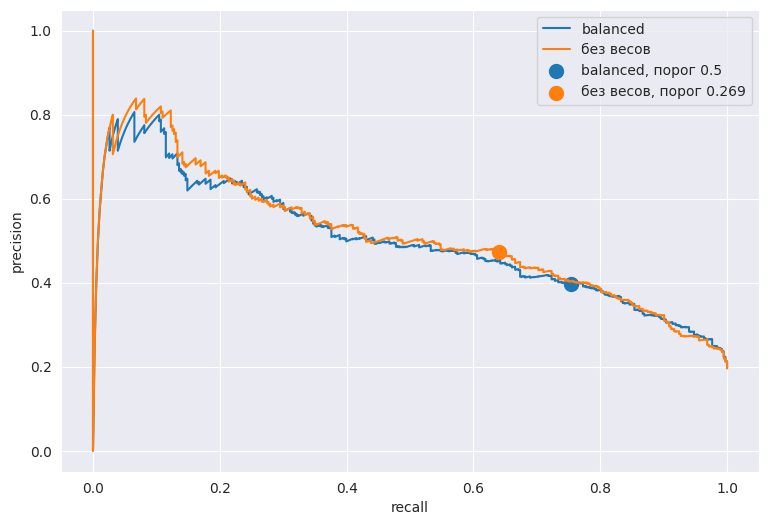

,модель,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,balanced,0.500000,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
1,без весов,0.268889,0.789744,0.473888,0.639687,0.544444,0.813537,0.512115


In [31]:
def evaluate_scores(name, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    return {
        'модель': name,
        'порог': threshold,
        'accuracy': metrics.accuracy_score(y_test, predictions),
        'precision': metrics.precision_score(
            y_test, predictions, zero_division=0
        ),
        'recall': metrics.recall_score(y_test, predictions),
        'F1': metrics.f1_score(
            y_test, predictions, zero_division=0
        ),
        'ROC-AUC': metrics.roc_auc_score(
            y_test, probabilities
        ),
        'PR-AUC': metrics.average_precision_score(
            y_test, probabilities
        )
    }

balanced_probabilities = model_with_weights.predict_proba(X_test)[:, 1]
unweighted_probabilities = final_wine_model.predict_proba(X_test)[:, 1]

balanced_precision, balanced_recall, _ = (
    metrics.precision_recall_curve(
        y_test, balanced_probabilities
    )
)

unweighted_precision, unweighted_recall, _ = (
    metrics.precision_recall_curve(
        y_test, unweighted_probabilities
    )
)

balanced_predictions = (
    balanced_probabilities >= 0.5
).astype(int)

unweighted_predictions = (
    unweighted_probabilities >= t_f1
).astype(int)

balanced_point = (
    metrics.recall_score(y_test, balanced_predictions),
    metrics.precision_score(y_test, balanced_predictions)
)

unweighted_point = (
    metrics.recall_score(y_test, unweighted_predictions),
    metrics.precision_score(y_test, unweighted_predictions)
)

plt.figure(figsize=(9, 6))
plt.plot(
    balanced_recall,
    balanced_precision,
    label='balanced'
)
plt.plot(
    unweighted_recall,
    unweighted_precision,
    label='без весов'
)
plt.scatter(
    *balanced_point,
    s=100,
    label='balanced, порог 0.5'
)
plt.scatter(
    *unweighted_point,
    s=100,
    label=f'без весов, порог {t_f1:.3f}'
)
plt.xlabel('recall')
plt.ylabel('precision')
plt.legend()
plt.show()

display(pd.DataFrame([
    evaluate_scores(
        'balanced',
        balanced_probabilities,
        0.5
    ),
    evaluate_scores(
        'без весов',
        unweighted_probabilities,
        t_f1
    )
]))

на PR-графике кривые моделей почти совпадают

у модели с весами и порогом 0,5 precision равен 0,397, recall равен 0,755
у модели без весов и с порогом 0,269 precision равен 0,474, recall равен 0,640

с весами модель находит больше хороших вин, но чаще добавляет в подборку неподходящие

можно сказать, что веса во многом действуют похоже на изменение порога
но эффект не совсем одинаковый: кривые и PR-AUC немного различаются

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [32]:
all_results = [
    evaluate_scores(
        'константная модель',
        np.zeros(len(y_test)),
        0.5
    ),
    evaluate_scores(
        'без весов',
        unweighted_probabilities,
        0.5
    ),
    evaluate_scores(
        'без весов, порог F1',
        unweighted_probabilities,
        t_f1
    ),
    evaluate_scores(
        'без весов, порог recall',
        unweighted_probabilities,
        t_r
    ),
    evaluate_scores(
        'наш LogReg',
        custom_wine_model.predict_proba(X_test_scaled)[:, 1],
        0.5
    ),
    evaluate_scores(
        'balanced',
        balanced_probabilities,
        0.5
    )
]

for name, model in resampling_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    all_results.append(
        evaluate_scores(name, probabilities, 0.5)
    )

all_results.append(
    evaluate_scores(
        'масштабирование, затем NearMiss',
        nearmiss_scaled_first.predict_proba(X_test)[:, 1],
        0.5
    )
)

all_models_table = pd.DataFrame(all_results)
display(all_models_table.sort_values('F1', ascending=False))

final_model = final_wine_model
final_threshold = float(t_f1)

print('выбранная модель: логистическая регрессия без весов')
print('выбранный порог:', final_threshold)

,модель,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
2,"без весов, порог F1",0.268889,0.789744,0.473888,0.639687,0.544444,0.813537,0.512115
3,"без весов, порог recall",0.243196,0.765128,0.436975,0.678851,0.531697,0.813537,0.512115
6,RandomUnderSampler,0.500000,0.729744,0.401099,0.762402,0.525653,0.809389,0.500528
9,SMOTE,0.500000,0.733846,0.404225,0.749347,0.525160,0.811607,0.508955
5,balanced,0.500000,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
8,RandomOverSampler,0.500000,0.726154,0.396433,0.754569,0.519784,0.811527,0.500264
7,NearMiss,0.500000,0.681026,0.351183,0.736292,0.475548,0.755049,0.393364
10,"масштабирование, затем NearMiss",0.500000,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
4,наш LogReg,0.500000,0.822051,0.607143,0.266319,0.370236,0.813518,0.512273
1,без весов,0.500000,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115


выбранная модель: логистическая регрессия без весов
выбранный порог: 0.2688887270064323


в общей таблице самый высокий F_1 у модели без весов с порогом 0,269, он равен 0,544

при этом precision равен 0,474, а recall равен 0,640
модель находит примерно 64% хороших вин

я бы предложила сервису эту модель и порог 0,269 как компромисс
при пороге 0,5 она находит только 26% хороших вин, а при более низком пороге 0,243 в подборку попадает ещё больше неподходящих вин

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [33]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = final_wine_model
final_threshold = float(t_f1)

joblib.dump(final_model, app_dir / 'model.joblib')

(app_dir / 'config.json').write_text(
    json.dumps({'threshold': final_threshold}),
    encoding='utf-8'
)

X_test.assign(target=y_test).to_csv(
    app_dir / 'test.csv',
    index=False
)
print([file.name for file in app_dir.iterdir()])

['test.csv', 'model.joblib', 'config.json']


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

Репозиторий с приложением: https://github.com/akecodn/logreg-streamlit